# The Cancer Genome Atlas (TCGA)

In [1]:
library(tidyverse)

suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))

suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(ComplexHeatmap))

suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1. Load Data

In [2]:
eSet <- readRDS("~/data1/TCGA/COAD/TCGA-COAD_RNAseq_eSet.rds")
eSet

class: SummarizedExperiment 
dim: 22160 514 
metadata(0):
assays(2): counts TPM
rownames(22160): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288670.1 ENSG00000288675.1
rowData names(3): gene_name gene_type basepairs
colnames(514): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(9): Source GroupNum ... T isOutlier

## 2. Data Exploration

In [3]:
rpk <- sweep(assay(eSet, "counts"), 1, rowData(eSet)$basepairs, FUN = "/")
assays(eSet)$TPM <- sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6
eSet

class: SummarizedExperiment 
dim: 22160 514 
metadata(0):
assays(2): counts TPM
rownames(22160): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288670.1 ENSG00000288675.1
rowData names(3): gene_name gene_type basepairs
colnames(514): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(9): Source GroupNum ... T isOutlier

In [4]:
geneSD <- apply(assay(eSet, "TPM"), 1, sd)
geneCV <- geneSD / rowMeans(assay(eSet, "TPM"))

In [5]:
# high_var_genes <- names(eSet)[geneCV > 20]
# length(high_var_genes)
top_var_genes <- names(eSet)[order(geneCV, decreasing = TRUE)][1:2000]
head(top_var_genes)

[1] "ENSG00000122133.17" "ENSG00000118137.10" "ENSG00000084674.15"
[4] "ENSG00000136696.11" "ENSG00000125255.7"  "ENSG00000203785.9"

In [6]:
eSet_topVar <- eSet[rownames(eSet) %in% top_var_genes, ]
ltpm <- log2(assay(eSet_topVar, "TPM") + 1)

In [7]:
ac <- colData(eSet) |> 
    as.data.frame() |> 
    dplyr::select("Group", "Stage", "Source", "M", "N", "T", "isOutlier")

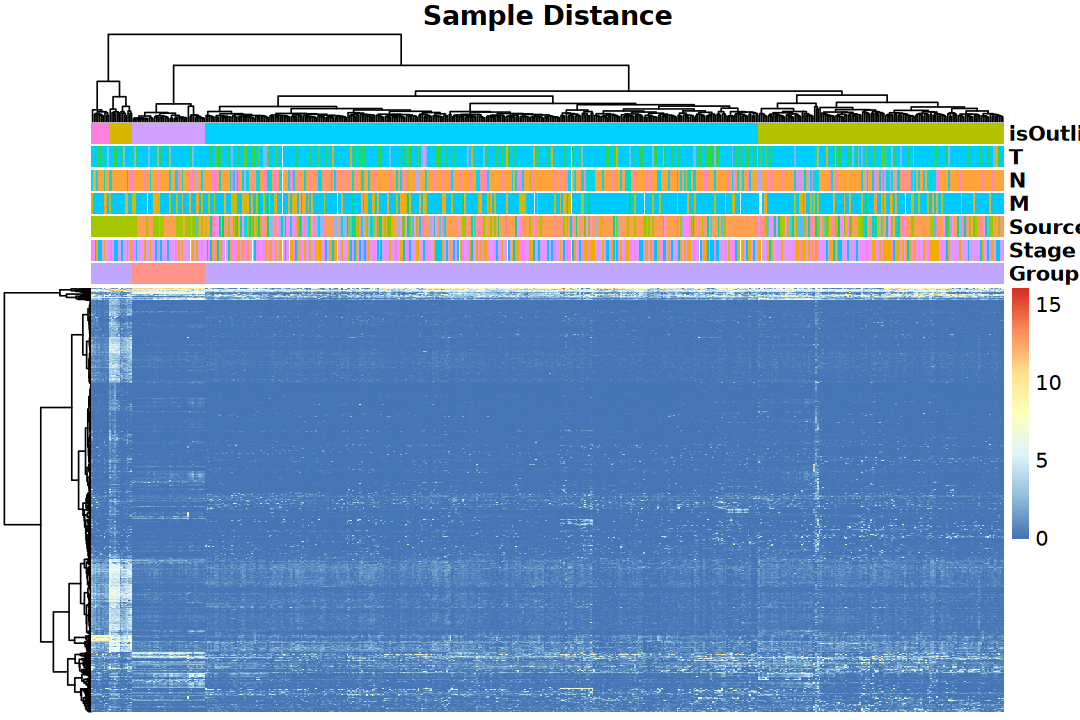

In [8]:
options(repr.plot.width = 9, repr.plot.height = 6)
ltpm_ht <- pheatmap::pheatmap(ltpm, 
                              clustering_method = "ward.D2",
                              annotation_col = ac, annotation_legend = FALSE,
                              main = "Sample Distance", fontsize = 12, 
                              show_colnames = FALSE, show_rownames = FALSE)

In [9]:
suppressPackageStartupMessages(library(ggdendro))
suppressPackageStartupMessages(library(ggnewscale))

In [10]:
ddata <- ggdendro::dendro_data(ltpm_ht$tree_col)
ddata$labels <- cbind(ddata$labels, ac[ddata$labels$label, ])

In [11]:
source_cols <- colorRampPalette(brewer.pal(12, "Set3"))(length(unique(ddata$labels$Source)))

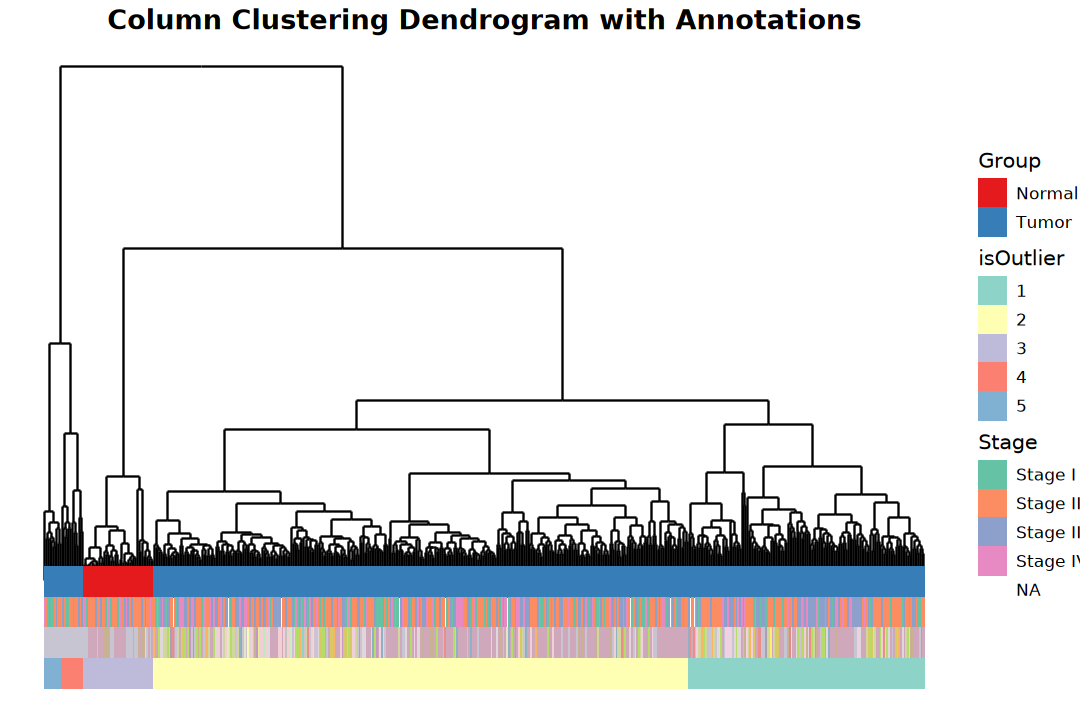

In [12]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot() + 
    geom_segment(data = segment(ddata), aes(x = x, y = y, xend = xend, yend = yend)) +
    geom_tile(data = ddata$labels, aes(x = x, y = -1, fill = Group), height = 30) +
    scale_fill_brewer(name = "Group", palette = "Set1") +
    ggnewscale::new_scale_fill() +
    geom_tile(data = ddata$labels, aes(x = x, y = -31, fill = Stage), height = 30) +
    scale_fill_brewer(name = "Stage", palette = "Set2") +
    ggnewscale::new_scale_fill() +
    geom_tile(data = ddata$labels, aes(x = x, y = -61, fill = Source), height = 30) +
    scale_fill_manual(name   = "Source", values = source_cols, guide  = "none") +
    ggnewscale::new_scale_fill() +
    geom_tile(data = ddata$labels, aes(x = x, y = -91, fill = isOutlier), height = 30) +
    scale_fill_brewer(name = "isOutlier", palette = "Set3") +
    labs(title = "Column Clustering Dendrogram with Annotations") +
    theme_void() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
          legend.title = element_text(size = 12),
          legend.text = element_text(size = 10),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank())

In [13]:
pca_res <- prcomp(ltpm, scale = TRUE)
percentVar <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)
pca_res <- merge(pca_res$rotation[,1:3], ac, by = "row.names")
# axisRange <- ceiling(max(abs(c(pcaData$PC1, pcaData$PC2))))

In [14]:
p1 <- ggplot(pca_res) +
    geom_point(aes(PC1, PC2, color = Group, shape = isOutlier), size = 3, na.rm = T) +
    xlab(paste0("PC1: ", percentVar[1], "% variance")) +
    ylab(paste0("PC2: ", percentVar[2], "% variance")) + 
    scale_color_brewer(palette = "Set2") +
    theme_test() +
    theme(text = element_text(size = 20))

In [15]:
p2 <- ggplot(pca_res) +
    geom_point(aes(PC1, PC2, color = isOutlier, shape = Group), size = 3, na.rm = T) +
    xlab(paste0("PC1: ", percentVar[1], "% variance")) +
    ylab(paste0("PC2: ", percentVar[2], "% variance")) + 
    scale_color_brewer(palette = "Set2") +
    theme_test() +
    theme(text = element_text(size = 20))

In [16]:
p3 <- ggplot(pca_res) +
    geom_point(aes(PC1, PC2, color = Stage, shape = Group), size = 3, na.rm = T) +
    xlab(paste0("PC1: ", percentVar[1], "% variance")) +
    ylab(paste0("PC2: ", percentVar[2], "% variance")) + 
    scale_color_brewer(palette = "Set2") +
    theme_test() +
    theme(text = element_text(size = 20))

In [17]:
p4 <- ggplot(pca_res) +
    geom_point(aes(PC1, PC2, color = Source, shape = Group), size = 3, na.rm = T) +
    xlab(paste0("PC1: ", percentVar[1], "% variance")) +
    ylab(paste0("PC2: ", percentVar[2], "% variance")) + 
    scale_fill_manual(name = "Source", values = source_cols) +
    theme_test() +
    theme(text = element_text(size = 20))

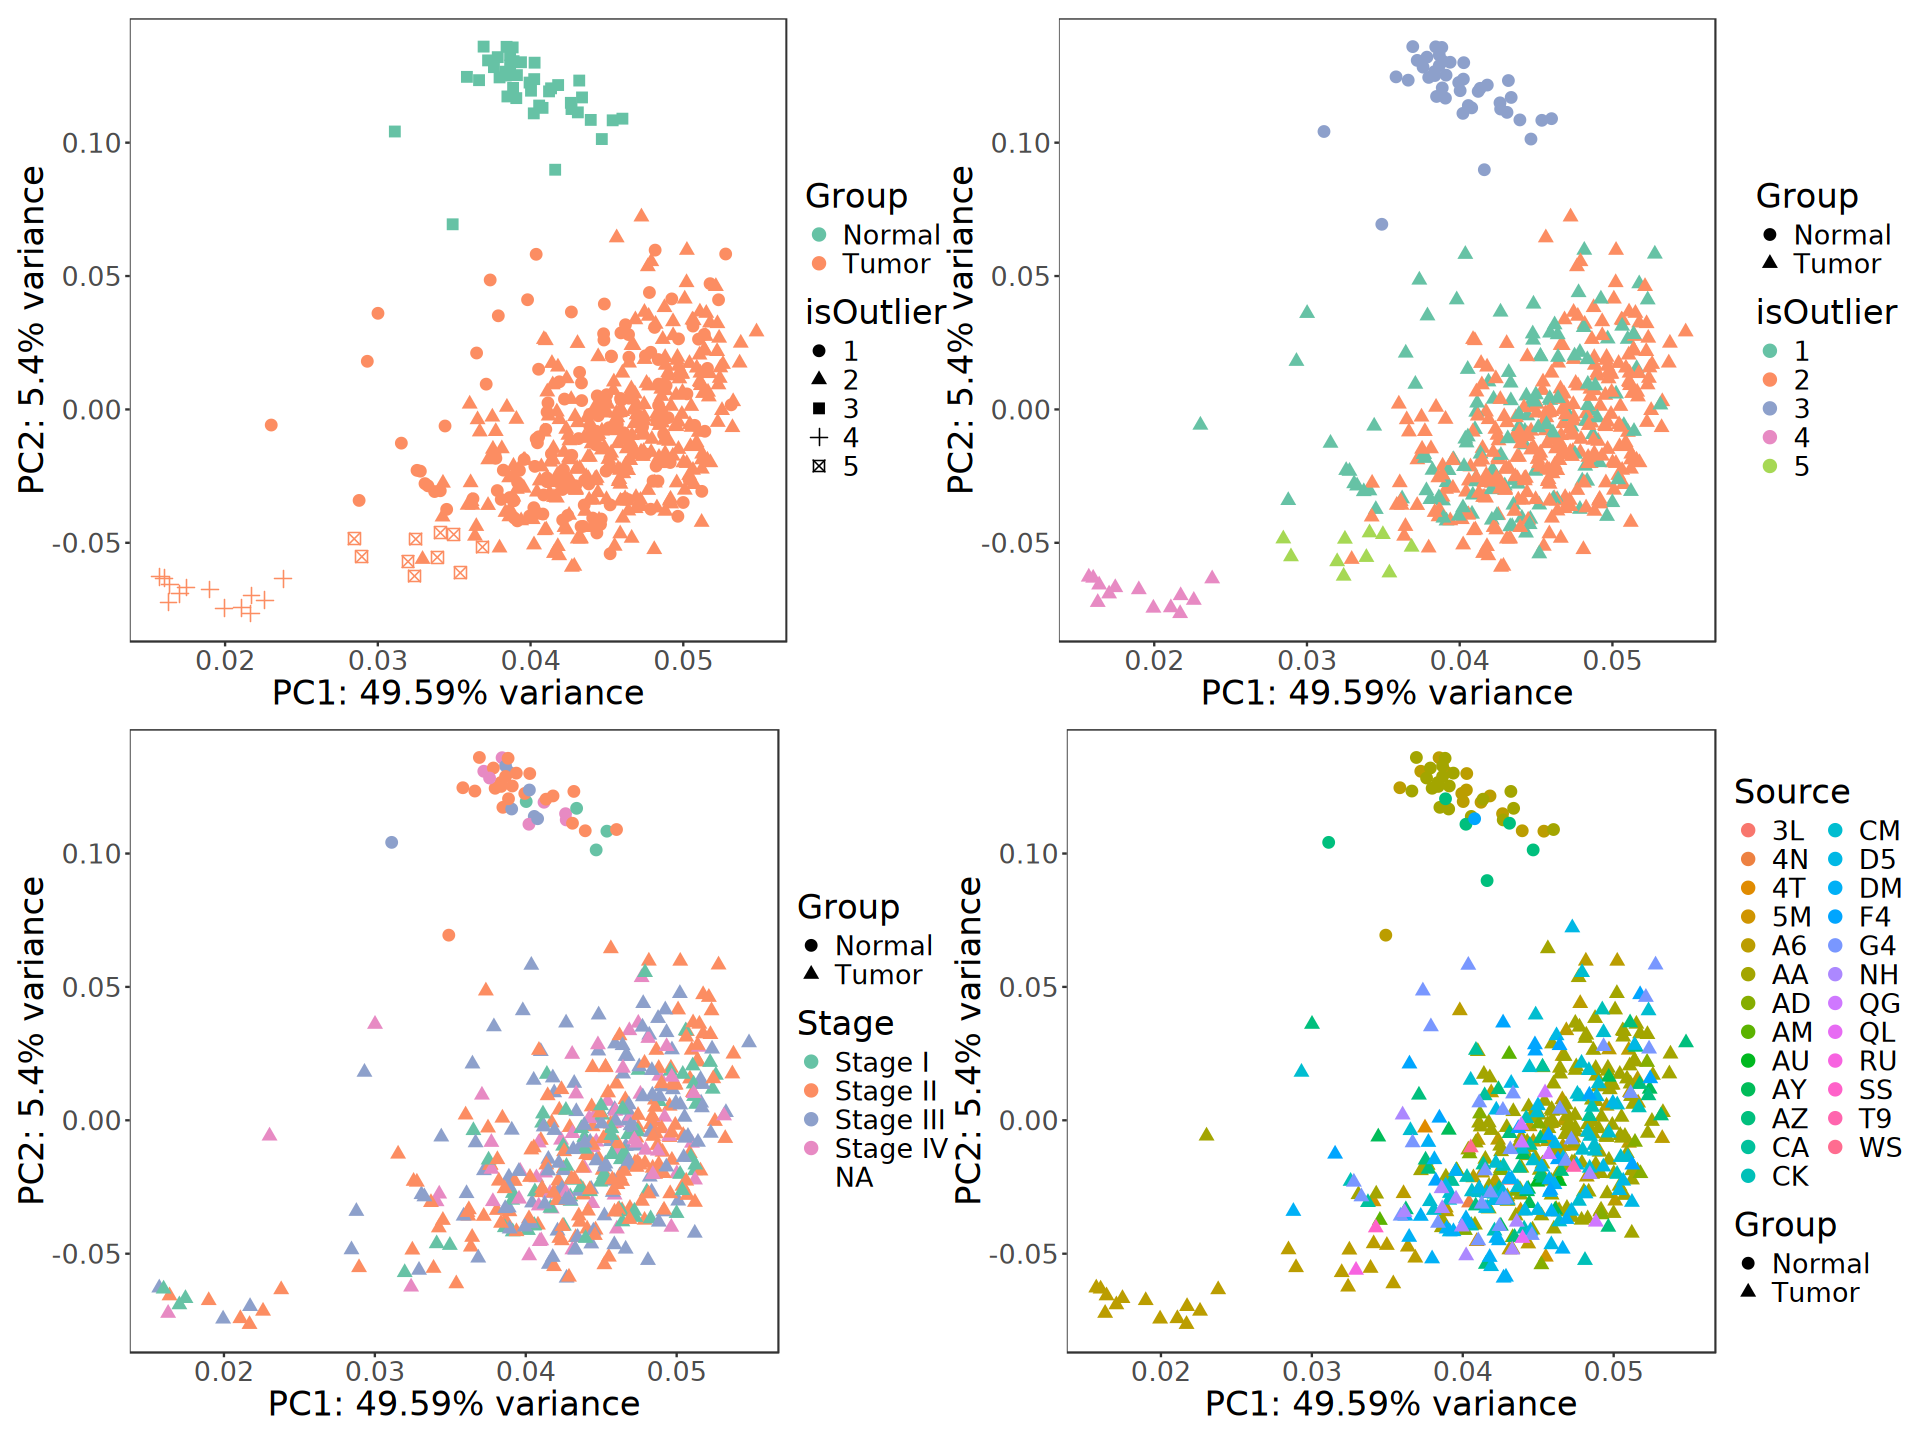

In [18]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2) / (p3 + p4)

## 3. Differential Gene Expression

In [19]:
logFC_thred <- log2(2)
q_thred <- 0.05

In [20]:
eSet_rmOut <- eSet[, eSet$isOutlier %in% c("1", "2", "3")]
eSet_rmOut

class: SummarizedExperiment 
dim: 22160 491 
metadata(0):
assays(2): counts TPM
rownames(22160): ENSG00000000003.15 ENSG00000000005.6 ...
  ENSG00000288670.1 ENSG00000288675.1
rowData names(3): gene_name gene_type basepairs
colnames(491): TCGA-5M-AAT6-01A TCGA-AA-3552-01A ... TCGA-AA-3715-01A
  TCGA-AA-3531-01A
colData names(9): Source GroupNum ... T isOutlier

### DESeq2

In [21]:
dds <- DESeqDataSet(eSet, design = ~ Group)
dds_rmOut <- DESeqDataSet(eSet_rmOut, design = ~ Group)

In [22]:
dds <- DESeq(dds)
dds_rmOut <- DESeq(dds_rmOut)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 1867 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 1118 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [23]:
res <- results(dds, lfcThreshold = logFC_thred, alpha = q_thred)
res_rmOut <- results(dds_rmOut, lfcThreshold = logFC_thred, alpha = q_thred)

In [24]:
res_deseq2 <- res |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    mutate(deg = ifelse(abs(log2FoldChange) > logFC_thred  & padj < q_thred, 
                        ifelse(log2FoldChange > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig"))) |>
    left_join(rowData(eSet) |> as.data.frame() |> rownames_to_column("gene_id"), by = "gene_id") |>
    column_to_rownames("gene_id")
table(res_deseq2$deg)


    Up   Down NotSig 
  2531   1798  17831 

In [25]:
res_deseq2_rmOut <- res_rmOut |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    mutate(deg = ifelse(abs(log2FoldChange) > logFC_thred  & padj < q_thred, 
                        ifelse(log2FoldChange > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig"))) |>
    left_join(rowData(eSet) |> as.data.frame() |> rownames_to_column("gene_id"), by = "gene_id") |>
    column_to_rownames("gene_id")
table(res_deseq2_rmOut$deg)


    Up   Down NotSig 
  2282   2047  17831 

In [26]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [27]:
genes <- list(Up = res_deseq2[res_deseq2$deg == "Up", "gene_name"], 
              Down = res_deseq2[res_deseq2$deg == "Down", "gene_name"],
              Up_rmOut = res_deseq2_rmOut[res_deseq2_rmOut$deg == "Up", "gene_name"],
              Down_rmOut = res_deseq2_rmOut[res_deseq2_rmOut$deg == "Down", "gene_name"])
genes <- lapply(genes, unique)

In [28]:
fill_colors <- brewer.pal(n = length(genes), name = "Set2")

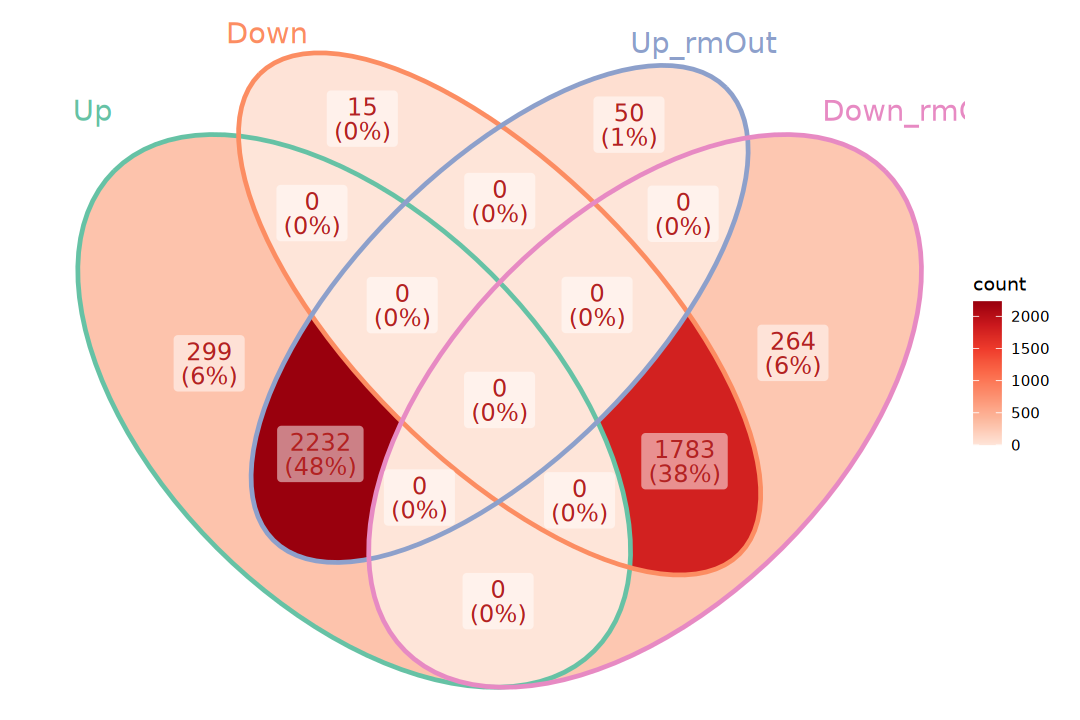

In [29]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram(genes, 
              set_color = fill_colors, set_size = 6, 
              label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

In [30]:
suppressPackageStartupMessages(library(UpSetR))

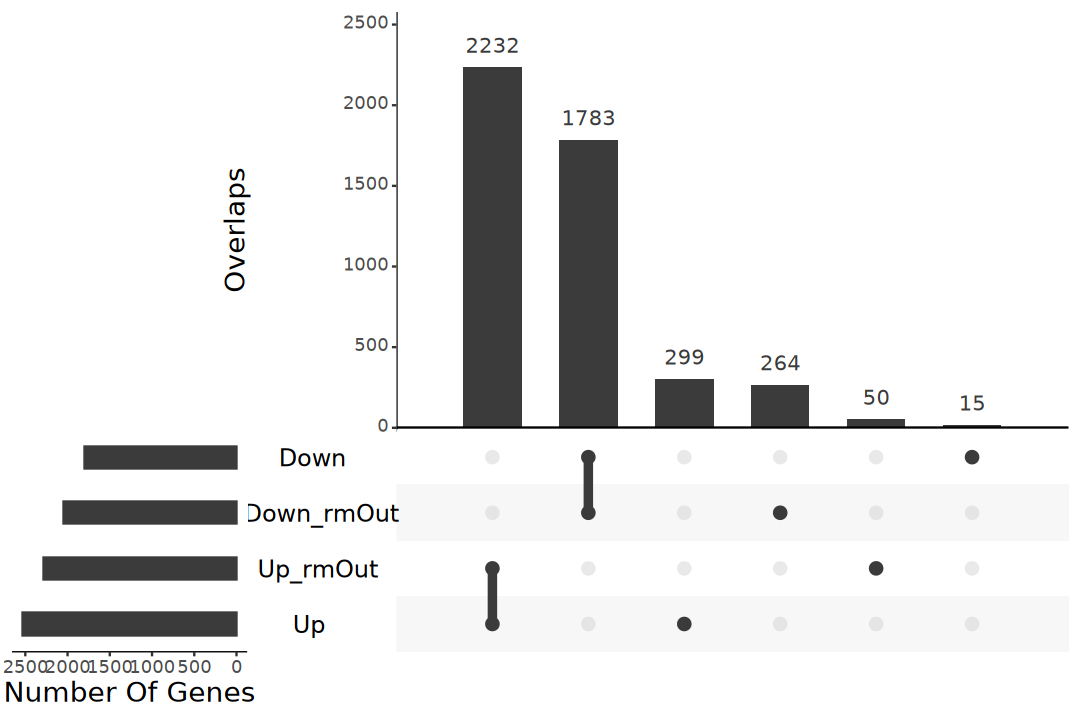

In [31]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))

### edgeR


In [32]:
dge <- DGEList(counts = assay(eSet, "counts"), 
               genes = rowData(eSet), 
               samples = colData(eSet), 
               group = colData(eSet)$Group)

dge_rmOut <- DGEList(counts = assay(eSet_rmOut, "counts"), 
                     genes = rowData(eSet_rmOut), 
                     samples = colData(eSet_rmOut), 
                     group = colData(eSet_rmOut)$Group)

In [33]:
# keep <- filterByExpr(dge)
# dge <- dge[keep, , keep.lib.sizes = FALSE]
dge <- calcNormFactors(dge)
dge_rmOut <- calcNormFactors(dge_rmOut)

In [34]:
design <- model.matrix(~ group, data = dge$samples)
design_rmOut <- model.matrix(~ group, data = dge_rmOut$samples)

In [35]:
dge <- estimateDisp(dge, design)
fit <- glmQLFit(dge, design)
qlf <- glmQLFTest(fit, coef = 2)

In [36]:
dge_rmOut <- estimateDisp(dge_rmOut, design_rmOut)
fit_rmOut <- glmQLFit(dge_rmOut, design_rmOut)
qlf_rmOut <- glmQLFTest(fit_rmOut, coef = 2)

In [37]:
res <- topTags(qlf, n = nrow(dge)) |> as.data.frame()
res_edgeR <- res |> 
    as.data.frame() |> 
    mutate(deg = ifelse(abs(logFC) > logFC_thred  & FDR < q_thred, 
                        ifelse(logFC > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig")))
table(res_edgeR$deg)


    Up   Down NotSig 
  4358   2933  14869 

In [38]:
res_rmOut <- topTags(qlf_rmOut, n = nrow(dge_rmOut)) |> as.data.frame()
res_edgeR_rmOut <- res_rmOut |> 
    as.data.frame() |> 
    mutate(deg = ifelse(abs(logFC) > logFC_thred  & FDR < q_thred, 
                        ifelse(logFC > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig")))
table(res_edgeR_rmOut$deg)


    Up   Down NotSig 
  4131   2955  15074 

In [39]:
genes <- list(Up = res_edgeR[res_edgeR$deg == "Up", "gene_name"], 
              Down = res_edgeR[res_edgeR$deg == "Down", "gene_name"],
              Up_rmOut = res_edgeR_rmOut[res_edgeR_rmOut$deg == "Up", "gene_name"],
              Down_rmOut = res_edgeR_rmOut[res_edgeR_rmOut$deg == "Down", "gene_name"])
genes <- lapply(genes, unique)

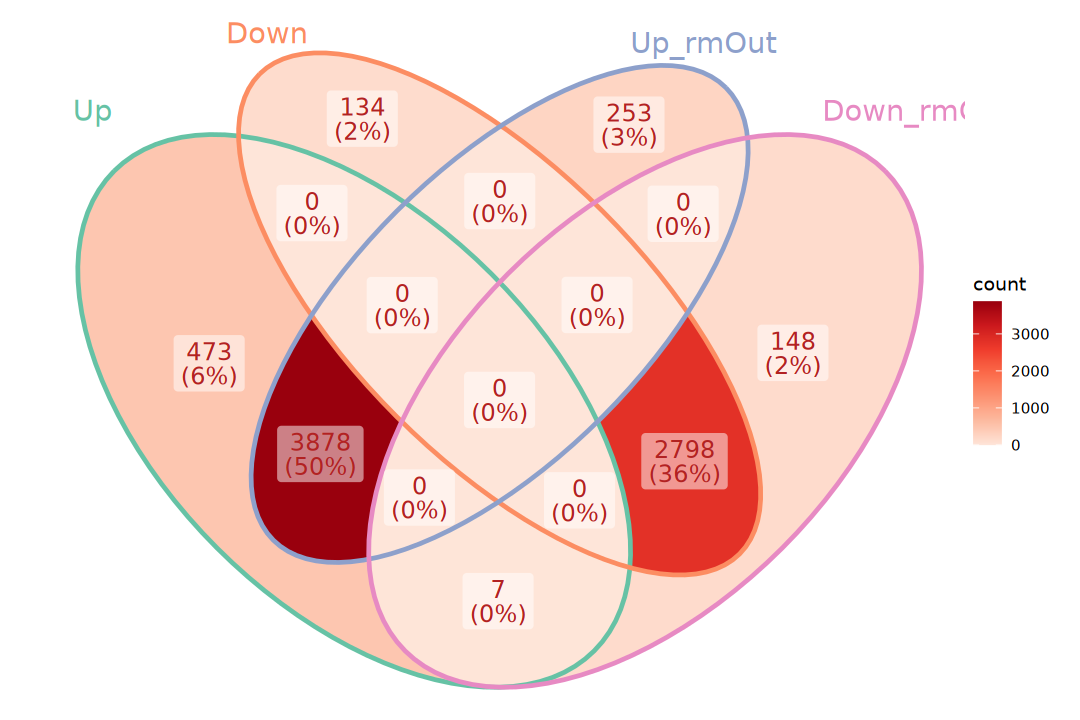

In [40]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram(genes, 
              set_color = fill_colors, set_size = 6, 
              label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

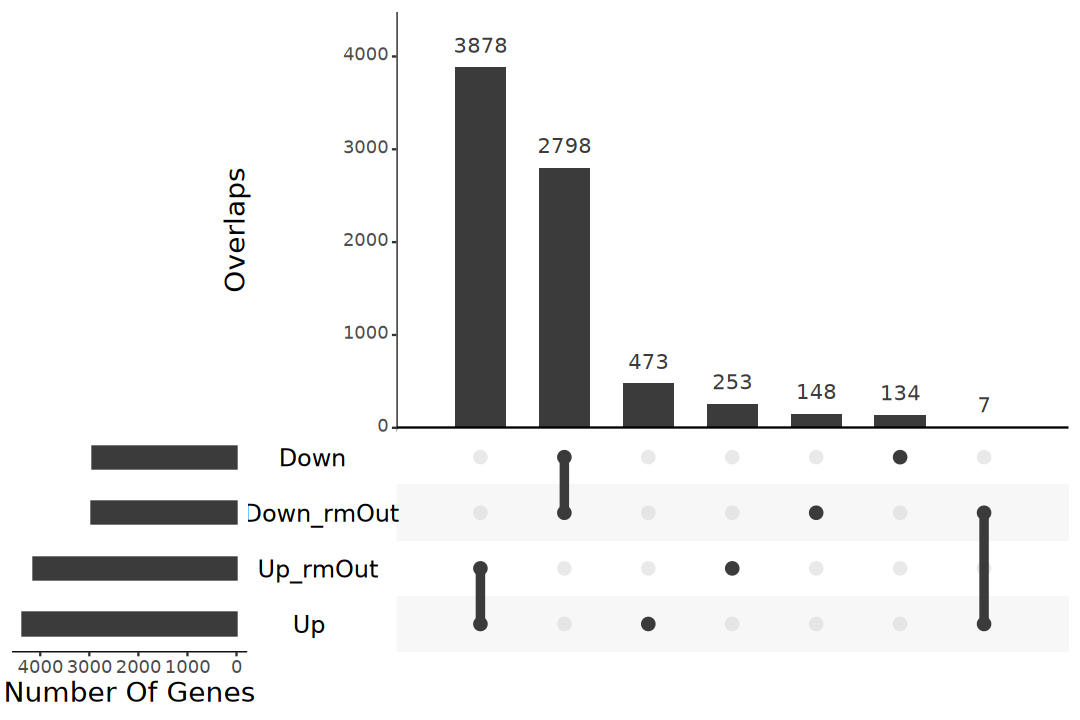

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))

### limma

In [42]:
design <- model.matrix(~ group, data = dge$samples)
design_rmOut <- model.matrix(~ group, data = dge_rmOut$samples)

In [43]:
deg_voom <- voom(dge, design, plot = FALSE)
vfit <- lmFit(deg_voom, design)
efit <- eBayes(vfit)

In [44]:
deg_voom_rmOut <- voom(dge_rmOut, design_rmOut, plot = FALSE)
vfit_rmOut <- lmFit(deg_voom_rmOut, design_rmOut)
efit_rmOut <- eBayes(vfit_rmOut)

In [45]:
res <- topTable(efit, coef = 2, n = Inf)
res_limma <- res |> 
    as.data.frame() |> 
    mutate(deg = ifelse(abs(logFC) > logFC_thred  & adj.P.Val < q_thred, 
                        ifelse(logFC > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig")))
table(res_limma$deg)


    Up   Down NotSig 
  2760   3995  15405 

In [46]:
res_rmOut <- topTable(efit_rmOut, coef = 2, n = Inf)
res_limma_rmOut <- res_rmOut |> 
    as.data.frame() |> 
    mutate(deg = ifelse(abs(logFC) > logFC_thred  & adj.P.Val < q_thred, 
                        ifelse(logFC > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig")))
table(res_limma_rmOut$deg)


    Up   Down NotSig 
  2931   3819  15410 

In [47]:
genes <- list(Up = res_limma[res_limma$deg == "Up", "gene_name"], 
              Down = res_limma[res_limma$deg == "Down", "gene_name"],
              Up_rmOut = res_limma_rmOut[res_limma_rmOut$deg == "Up", "gene_name"],
              Down_rmOut = res_limma_rmOut[res_limma_rmOut$deg == "Down", "gene_name"])
genes <- lapply(genes, unique)

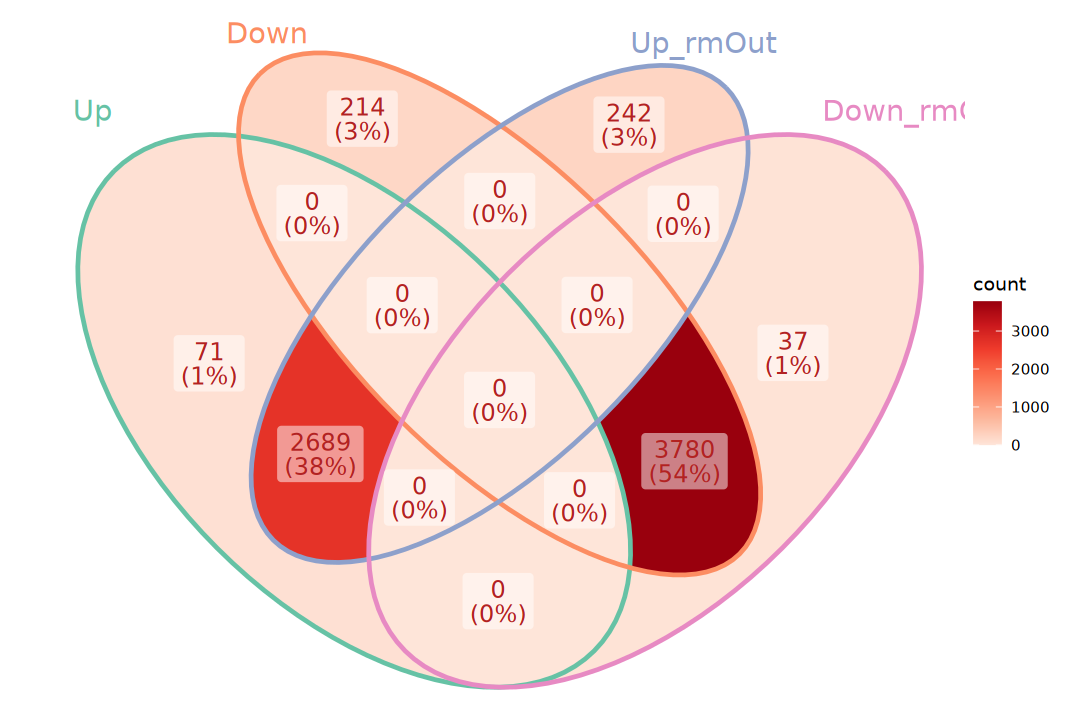

In [48]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram(genes, 
              set_color = fill_colors, set_size = 6, 
              label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

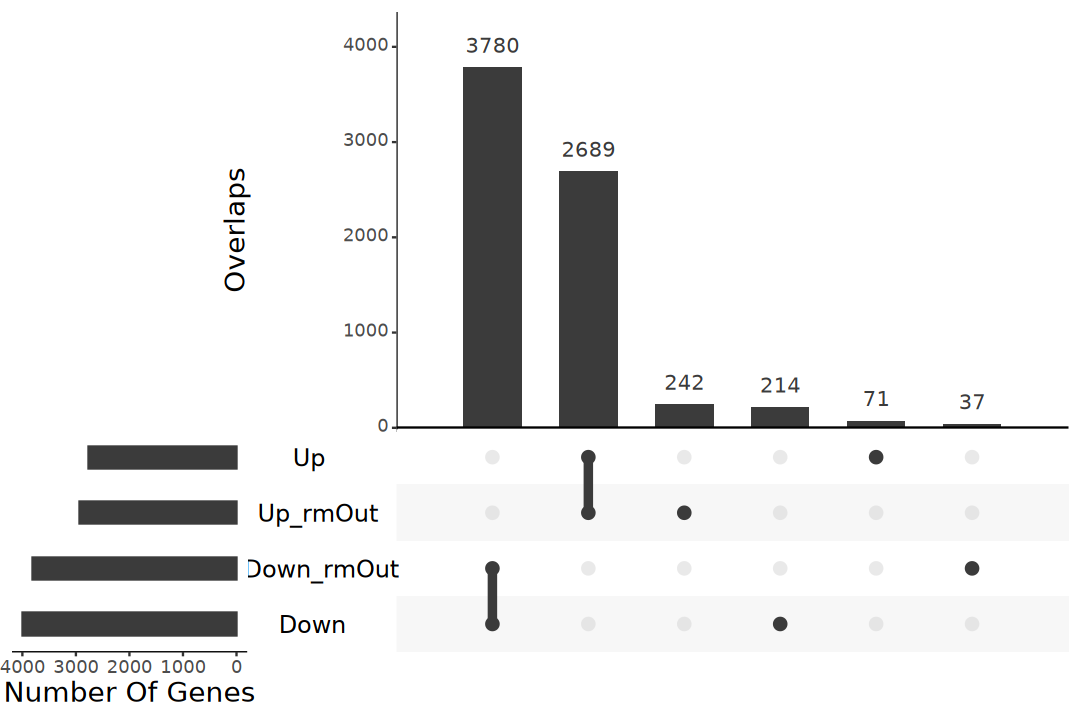

In [49]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))

### Wilcoxon test

In [50]:
# TPM
# normalized_matrix <- assays(eSet)$TPM
# DESeq2 normalization
# normalized_matrix <- counts(dds, normalized = TRUE)
# edgeR TMM
normalized_matrix <- cpm(dge, method = "TMM")
normalized_matrix_rmOut <- cpm(dge_rmOut, method = "TMM")

In [51]:
group_levels <- levels(colData(eSet)$Group)

In [52]:
controlDat <- normalized_matrix[, colnames(eSet)[which(eSet$Group == group_levels[1])]]
treatDat <- normalized_matrix[, colnames(eSet)[which(eSet$Group == group_levels[2])]]

controlDat_rmOut <- normalized_matrix_rmOut[, colnames(eSet_rmOut)[which(eSet_rmOut$Group == group_levels[1])]]
treatDat_rmOut <- normalized_matrix_rmOut[, colnames(eSet_rmOut)[which(eSet_rmOut$Group == group_levels[2])]]

In [53]:
all(colnames(normalized_matrix) == colnames(eSet))
all(colnames(normalized_matrix_rmOut) == colnames(eSet_rmOut))

[1] TRUE

[1] TRUE

In [54]:
res <- apply(normalized_matrix, 1, function(gene_expr) {
    test <- wilcox.test(gene_expr ~ eSet$Group)
    c(p.value = test$p.value, stat = test$statistic)
}) |> t() |> as.data.frame()

res$adj.P.Val <- p.adjust(res$p.value, method = "fdr")

res$logFC <- log2(rowMeans(treatDat) / rowMeans(controlDat))

In [55]:
res_rmOut <- apply(normalized_matrix_rmOut, 1, function(gene_expr) {
    test <- wilcox.test(gene_expr ~ eSet_rmOut$Group)
    c(p.value = test$p.value, stat = test$statistic)
}) |> t() |> as.data.frame()

res_rmOut$adj.P.Val <- p.adjust(res_rmOut$p.value, method = "fdr")

res_rmOut$logFC <- log2(rowMeans(treatDat_rmOut) / rowMeans(controlDat_rmOut))

In [56]:
result_wilcox <- res |> 
    rownames_to_column("gene_id") |> 
    mutate(deg = ifelse(abs(logFC) > logFC_thred  & adj.P.Val < q_thred, 
                        ifelse(logFC > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig"))) |>
    left_join(rowData(eSet) |> as.data.frame() |> rownames_to_column("gene_id"), by = "gene_id") |>
    column_to_rownames("gene_id")    
table(result_wilcox$deg)


    Up   Down NotSig 
  3766   2958  15436 

In [57]:
result_wilcox_rmOut <- res_rmOut |> 
    rownames_to_column("gene_id") |> 
    mutate(deg = ifelse(abs(logFC) > logFC_thred  & adj.P.Val < q_thred, 
                        ifelse(logFC > logFC_thred, "Up", "Down"), "NotSig") |> 
               factor(levels = c("Up", "Down", "NotSig"))) |>
    left_join(rowData(eSet) |> as.data.frame() |> rownames_to_column("gene_id"), by = "gene_id") |>
    column_to_rownames("gene_id")    
table(result_wilcox_rmOut$deg)


    Up   Down NotSig 
  3773   2971  15416 

In [58]:
genes <- list(Up = result_wilcox[result_wilcox$deg == "Up", "gene_name"], 
              Down = result_wilcox[result_wilcox$deg == "Down", "gene_name"],
              Up_rmOut = result_wilcox_rmOut[result_wilcox_rmOut$deg == "Up", "gene_name"],
              Down_rmOut = result_wilcox_rmOut[result_wilcox_rmOut$deg == "Down", "gene_name"])
genes <- lapply(genes, unique)

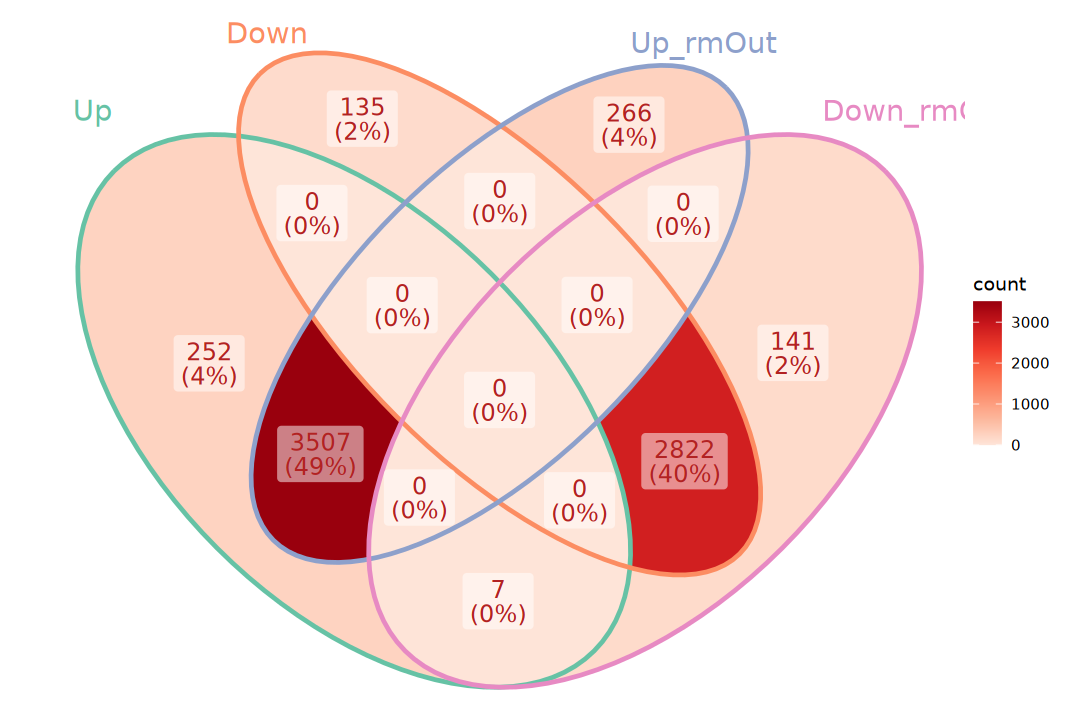

In [59]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggVennDiagram(genes, 
              set_color = fill_colors, set_size = 6, 
              label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

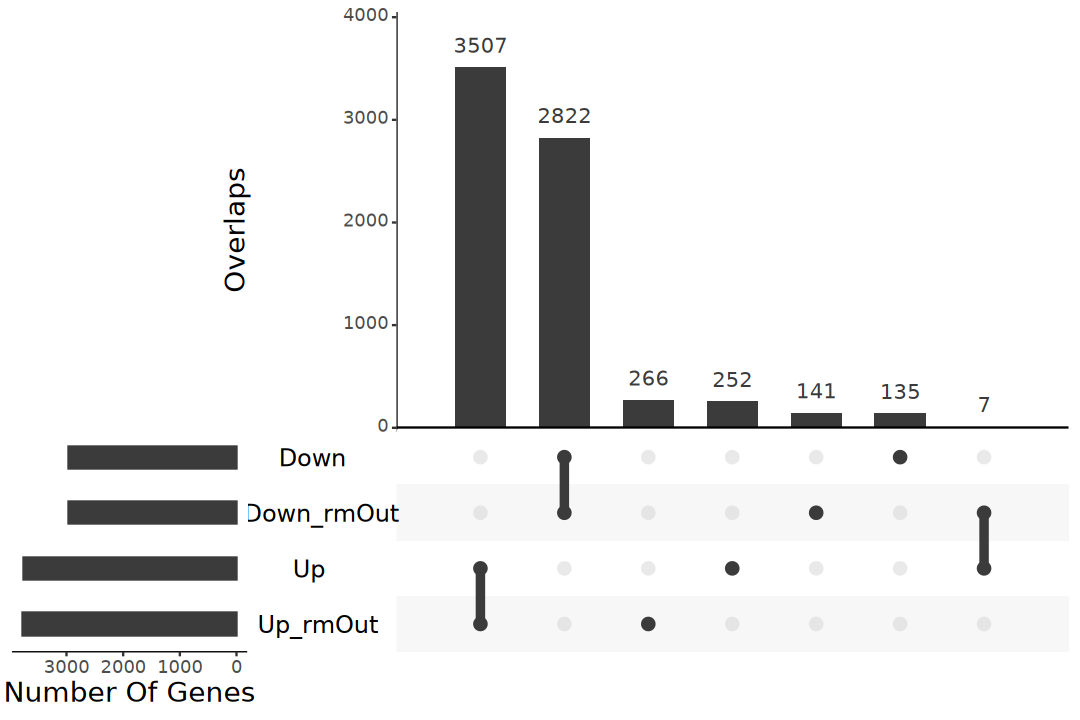

In [60]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))

### Venn / UpSet

In [61]:
genes_up <- list(DESeq2 = res_deseq2[res_deseq2$deg == "Up", "gene_name"], 
                 DESeq2_rmOut = res_deseq2_rmOut[res_deseq2_rmOut$deg == "Up", "gene_name"], 
                 edgeR = res_edgeR[res_edgeR$deg == "Up", "gene_name"],
                 edgeR_rmOut = res_edgeR_rmOut[res_edgeR_rmOut$deg == "Up", "gene_name"],
                 limma = res_limma[res_limma$deg == "Up", "gene_name"],
                 limma_rmOut = res_limma_rmOut[res_limma_rmOut$deg == "Up", "gene_name"],
                 wilcox = result_wilcox[result_wilcox$deg == "Up", "gene_name"],
                 wilcox_rmOut = result_wilcox_rmOut[result_wilcox_rmOut$deg == "Up", "gene_name"])
genes_up <- lapply(genes_up, unique)

In [62]:
genes_down <- list(DESeq2 = res_deseq2[res_deseq2$deg == "Down", "gene_name"], 
                   DESeq2_rmOut = res_deseq2_rmOut[res_deseq2_rmOut$deg == "Down", "gene_name"], 
                   edgeR = res_edgeR[res_edgeR$deg == "Down", "gene_name"],
                   edgeR_rmOut = res_edgeR_rmOut[res_edgeR_rmOut$deg == "Down", "gene_name"],
                   limma = res_limma[res_limma$deg == "Down", "gene_name"],
                   limma_rmOut = res_limma_rmOut[res_limma_rmOut$deg == "Down", "gene_name"],
                   wilcox = result_wilcox[result_wilcox$deg == "Down", "gene_name"],
                   wilcox_rmOut = result_wilcox_rmOut[result_wilcox_rmOut$deg == "Down", "gene_name"])
genes_down <- lapply(genes_down, unique)

In [63]:
suppressPackageStartupMessages(library(eulerr))

In [64]:
fill_colors <- brewer.pal(n = length(genes_up), name = "Set1")

In [65]:
fit <- euler(genes_up)

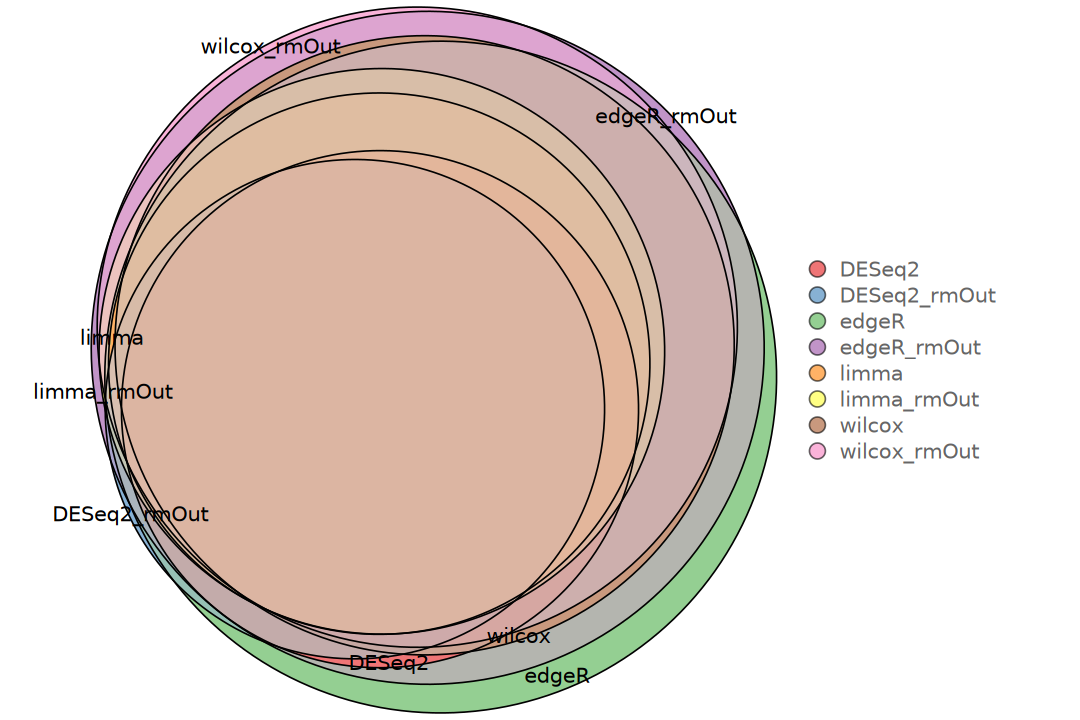

In [66]:
options(repr.plot.width = 9, repr.plot.height = 6)
plot(fit, 
     fills = list(fill = fill_colors, alpha = 0.6),
     labels = list(font = 12), 
     # quantities = list(type = c("percent", "counts"), font = 12),
     legend = list(side = "right"))

In [67]:
fit <- euler(genes_down)

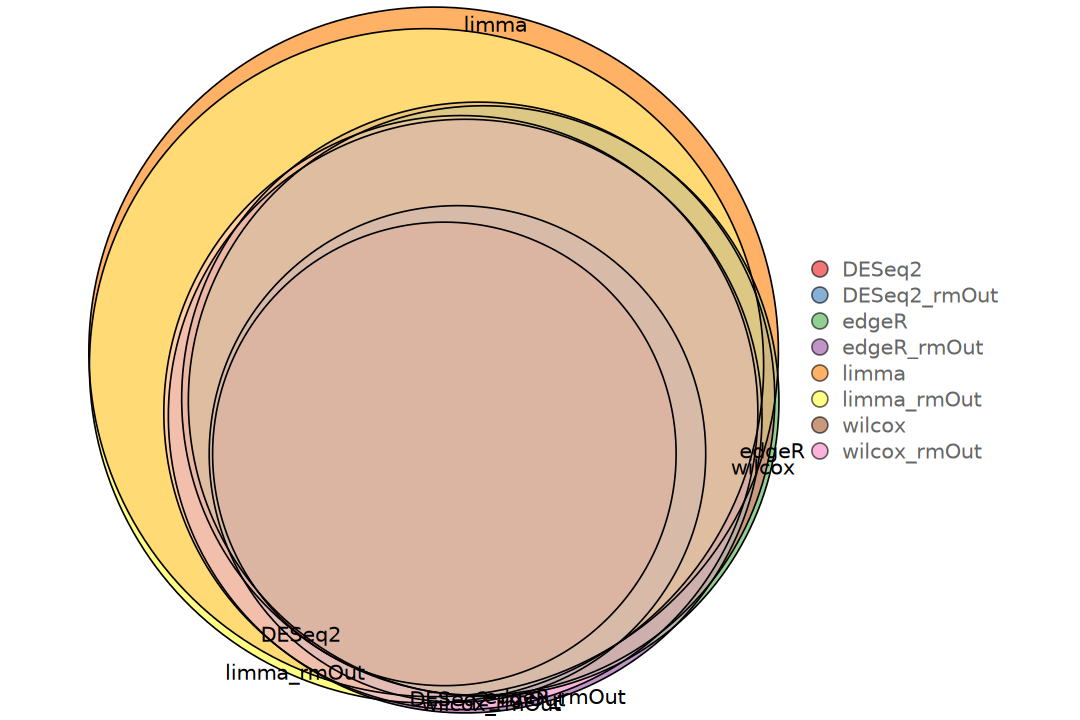

In [68]:
options(repr.plot.width = 9, repr.plot.height = 6)
plot(fit, 
     fills = list(fill = fill_colors, alpha = 0.6),
     labels = list(font = 12), 
     # quantities = list(type = c("percent", "counts"), font = 12),
     legend = list(side = "right"))

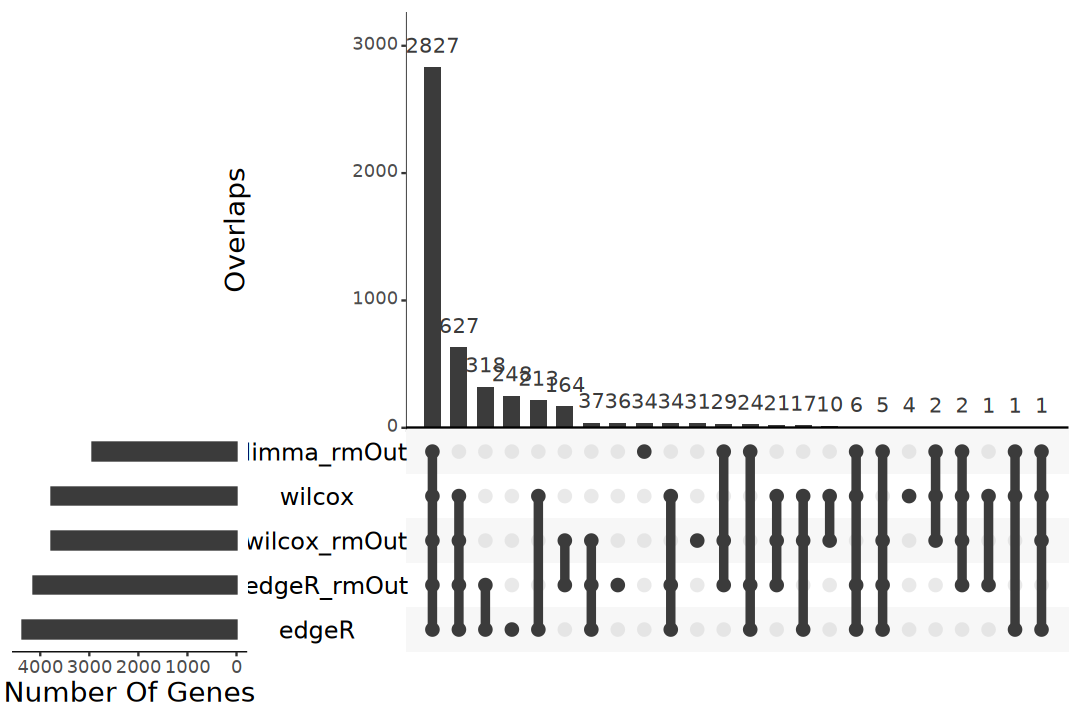

In [69]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes_up), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))

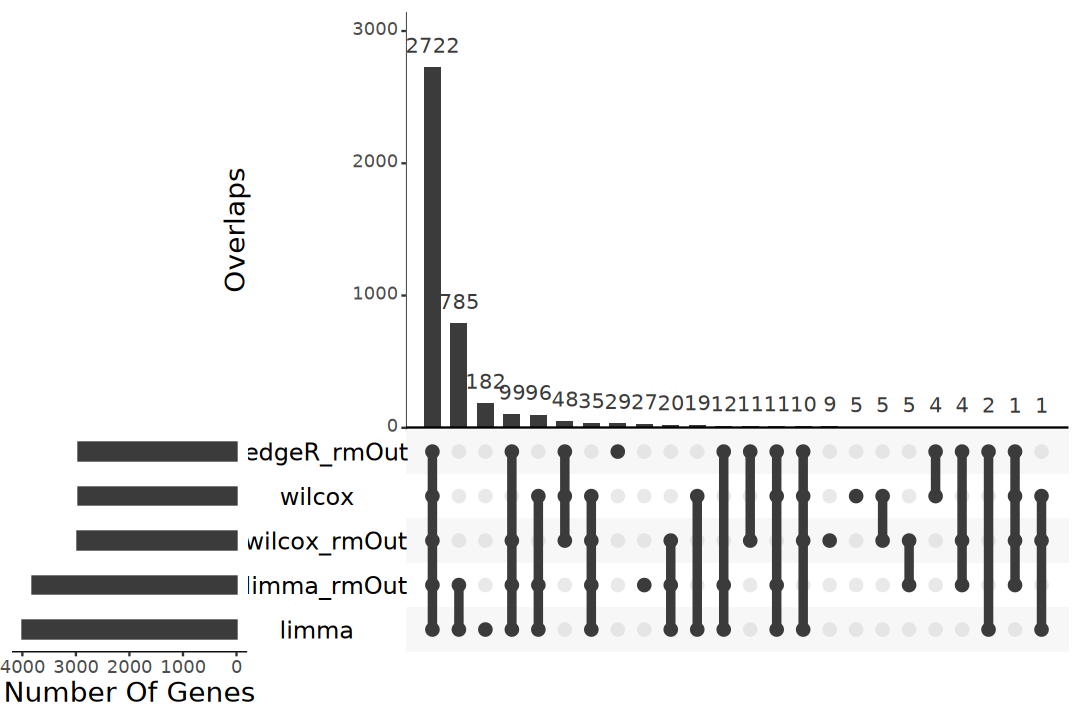

In [70]:
options(repr.plot.width = 9, repr.plot.height = 6)
upset(fromList(genes_down), sets.x.label = "Number Of Genes", mainbar.y.label = "Overlaps", 
      order.by = "freq", keep.order = TRUE, mb.ratio = c(0.6, 0.4), 
      point.size = 3.5, line.size = 2, text.scale = c(2, 1.5, 2, 1.5, 2, 2))